# Proyek Analisis Data: E-Commerce Public Dataset (Olist Brasil)
- **Nama:** Andi Muh. Daffa' Dermawan
- **Dataset:** E-Commerce Public Dataset (Brazilian E-Commerce oleh Olist)

**Ringkasan proyek.** Proyek ini menganalisis transaksi marketplace Olist di Brasil untuk membantu tim bisnis menentukan (1) kategori produk yang perlu diprioritaskan, (2) arah tren permintaan, dan (3) wilayah dengan kualitas layanan logistik yang perlu diperbaiki. Teknik analisis lanjutan yang digunakan: **RFM Analysis**, **Geospatial Analysis**, serta **Clustering manual (manual grouping & binning)**.

## Menentukan Pertanyaan Bisnis

Seluruh pertanyaan dirumuskan dengan kerangka **SMART** (Specific, Measurable, Action-Oriented, Relevant, Time-bound). Cakupan waktu analisis adalah **Januari 2017 – Agustus 2018** (hanya pesanan berstatus *delivered*), karena data tahun 2016 dan September–Oktober 2018 sangat sedikit sehingga tidak representatif.

- **Pertanyaan 1:** Kategori produk apa saja yang menghasilkan revenue (jumlah `price`) tertinggi dan terendah (5 teratas dan 5 terbawah) selama Januari 2017 – Agustus 2018, dan berapa persen kontribusi masing-masing terhadap total revenue, sehingga tim merchandising dapat memprioritaskan stok dan promosi?
- **Pertanyaan 2:** Bagaimana tren jumlah order dan total revenue bulanan selama Januari 2017 – Agustus 2018, bulan apa yang mencapai puncak, dan berapa pertumbuhan *Month-over-Month* (MoM)-nya, sehingga tim operasional dapat merencanakan kapasitas dan kampanye musiman?
- **Pertanyaan 3:** Di negara bagian (*state*) mana skor review rata-rata paling rendah dan persentase pesanan terlambat (tiba setelah estimasi) paling tinggi selama Januari 2017 – Agustus 2018, dan seberapa besar pengaruh keterlambatan terhadap skor review, sehingga tim logistik dapat menentukan wilayah dan batas waktu pengiriman yang perlu diperbaiki?

**Pemenuhan unsur SMART:**

| Unsur | Pertanyaan 1 | Pertanyaan 2 | Pertanyaan 3 |
|---|---|---|---|
| Specific | Kategori produk, revenue, 5 teratas/terbawah | Order & revenue bulanan, puncak, MoM | Skor review & % terlambat per state |
| Measurable | Revenue (R$) dan % kontribusi | Jumlah order, revenue, % MoM | Skor 1–5, % pesanan terlambat |
| Action-Oriented | Prioritas stok & promosi | Perencanaan kapasitas & kampanye | Perbaikan logistik wilayah tertentu |
| Relevant | Pendapatan marketplace | Pertumbuhan bisnis | Kepuasan pelanggan & retensi |
| Time-bound | Jan 2017 – Agu 2018 | Jan 2017 – Agu 2018 | Jan 2017 – Agu 2018 |

## Import Semua Packages/Library yang Digunakan

In [4]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="white")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

def rnd(df, n=2):
    # membulatkan hanya kolom numerik agar kolom teks tidak menimbulkan error
    return df.apply(lambda s: s.round(n) if pd.api.types.is_numeric_dtype(s) else s)

HIGHLIGHT = "#72BCD4"   # warna sorotan
MUTED = "#D3D3D3"       # warna netral
ALERT = "#E4572E"       # warna peringatan (nilai buruk)
DATA_DIR = "data/"


**Penjelasan:** `pandas` dan `numpy` digunakan untuk pengolahan data, sedangkan `matplotlib` dan `seaborn` untuk visualisasi. Palet warna dibuat konsisten: biru muda untuk sorotan, abu-abu untuk data pembanding, dan merah untuk kondisi buruk.

## Data Wrangling

### Gathering Data

Pada tahap ini seluruh tabel yang relevan dimuat ke dalam *DataFrame*: pesanan (`orders`), item pesanan (`order_items`), pelanggan (`customers`), produk (`products`), terjemahan kategori (`category_translation`), ulasan (`order_reviews`), dan geolokasi (`geolocation`).

#### Load seluruh dataset

In [5]:
orders_df = pd.read_csv(DATA_DIR + "orders_dataset.csv")
items_df = pd.read_csv(DATA_DIR + "order_items_dataset.csv")
customers_df = pd.read_csv(DATA_DIR + "customers_dataset.csv")
products_df = pd.read_csv(DATA_DIR + "products_dataset.csv")
translation_df = pd.read_csv(DATA_DIR + "product_category_name_translation.csv")
reviews_df = pd.read_csv(DATA_DIR + "order_reviews_dataset.csv")
geo_df = pd.read_csv(DATA_DIR + "geolocation_dataset.csv")

tables = {"orders": orders_df, "order_items": items_df, "customers": customers_df,
          "products": products_df, "translation": translation_df,
          "reviews": reviews_df, "geolocation": geo_df}
pd.DataFrame({"jumlah_baris": {k: v.shape[0] for k, v in tables.items()},
              "jumlah_kolom": {k: v.shape[1] for k, v in tables.items()}})

,jumlah_baris,jumlah_kolom
orders,99441,8
order_items,112650,7
customers,99441,5
products,32951,9
translation,71,2
reviews,99224,7
geolocation,1000163,5


In [6]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:**
- Dataset terdiri dari 7 tabel yang saling terhubung lewat `order_id`, `customer_id`, dan `product_id`: 99.441 pesanan, 112.650 item pesanan, dan 99.441 pelanggan.
- Tabel `geolocation` adalah yang terbesar (sekitar 1 juta baris) sehingga perlu diagregasi sebelum dipakai untuk analisis geospasial.
- Satu pesanan dapat memuat beberapa item, jadi jumlah order harus dihitung dengan `nunique` pada `order_id`, bukan jumlah baris.

### Assessing Data

Tahap ini menilai kualitas data: tipe data, *missing value*, data duplikat, nilai tidak konsisten/tidak valid, dan *outlier*.

#### Identifying missing value & tipe data

In [7]:
for name in ["orders", "products", "reviews"]:
    df = tables[name]
    miss = df.isna().sum()
    print(f"=== {name} ===")
    print(miss[miss > 0].to_string() if miss.sum() else "tidak ada missing value", "\n")

print("Tipe data kolom tanggal pada orders:")
print(orders_df.dtypes[orders_df.columns.str.contains("date|timestamp|_at")])

=== orders ===
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965 

=== products ===
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2 

=== reviews ===
review_comment_title      87656
review_comment_message    58247 

Tipe data kolom tanggal pada orders:
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object


In [8]:
print("Distribusi status pesanan:")
print(orders_df["order_status"].value_counts(), "\n")

delivered_raw = orders_df[orders_df["order_status"] == "delivered"]
print("Pesanan 'delivered' tanpa tanggal tiba di pelanggan:", delivered_raw["order_delivered_customer_date"].isna().sum())

print("\nJumlah order per bulan (delivered):")
print(delivered_raw["order_purchase_timestamp"].str[:7].value_counts().sort_index().to_string())

Distribusi status pesanan:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64 

Pesanan 'delivered' tanpa tanggal tiba di pelanggan: 8

Jumlah order per bulan (delivered):
order_purchase_timestamp
2016-09       1
2016-10     265
2016-12       1
2017-01     750
2017-02    1653
2017-03    2546
2017-04    2303
2017-05    3546
2017-06    3135
2017-07    3872
2017-08    4193
2017-09    4150
2017-10    4478
2017-11    7289
2017-12    5513
2018-01    7069
2018-02    6555
2018-03    7003
2018-04    6798
2018-05    6749
2018-06    6099
2018-07    6159
2018-08    6351


#### Identifying duplicate data

In [9]:
print("Baris duplikat penuh:")
for name, df in tables.items():
    print(f"  {name:12s}: {df.duplicated().sum()}")

print("\nOrder dengan lebih dari satu review (order_id duplikat di reviews):", reviews_df["order_id"].duplicated().sum())

Baris duplikat penuh:
  orders      : 0
  order_items : 0
  customers   : 0
  products    : 0
  translation : 0
  reviews     : 0
  geolocation : 261831

Order dengan lebih dari satu review (order_id duplikat di reviews): 551


#### Identifying inconsistent / invalid value & outlier

In [10]:
# 1) Kategori produk yang tidak punya terjemahan
missing_trans = set(products_df["product_category_name"].dropna()) - set(translation_df["product_category_name"])
print("Kategori tanpa terjemahan:", missing_trans)

# 2) Outlier harga item (metode IQR)
q1, q3 = items_df["price"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"\nBatas atas outlier harga (IQR): R$ {upper:.2f}; jumlah item di atasnya: {(items_df['price'] > upper).sum()} "
      f"({(items_df['price'] > upper).mean():.1%}); harga maksimum: R$ {items_df['price'].max():.2f}")

# 3) Koordinat geolokasi di luar wilayah Brasil
out_geo = geo_df[(geo_df["geolocation_lat"] > 5.3) | (geo_df["geolocation_lat"] < -33.8) |
                 (geo_df["geolocation_lng"] > -34.7) | (geo_df["geolocation_lng"] < -73.9)]
print("\nKoordinat di luar bounding box Brasil:", len(out_geo))

Kategori tanpa terjemahan: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}

Batas atas outlier harga (IQR): R$ 277.40; jumlah item di atasnya: 8427 (7.5%); harga maksimum: R$ 6735.00

Koordinat di luar bounding box Brasil: 42


**Steps to Take (rencana pembersihan):**
- **Tipe data tidak sesuai:** kolom tanggal masih bertipe teks (`object`/`str`) → ubah ke `datetime`.
- **Missing value pada `orders`:** pesanan *delivered* tanpa tanggal tiba (8 baris) tidak dapat dihitung ketepatan waktunya → hapus. Status lain (*shipped*, *canceled*, dst.) memang belum/tidak sampai sehingga dikeluarkan dari analisis karena belum menjadi revenue yang terealisasi.
- **Missing value pada `products`:** kategori kosong (610 produk) → isi dengan `unknown` agar revenue-nya tetap terhitung dan transparan.
- **Nilai tidak konsisten:** nama kategori berbahasa Portugis dan 2 kategori tidak punya terjemahan → terjemahkan ke Inggris dan lengkapi 2 terjemahan secara manual.
- **Duplikat:** tabel `reviews` memiliki beberapa review untuk satu `order_id` → pertahankan review terbaru. Tabel `geolocation` memiliki ratusan ribu baris duplikat → hapus duplikat.
- **Outlier:** koordinat di luar Brasil → dibuang. Harga tinggi (barang mahal) adalah transaksi nyata dan bukan kesalahan input, sehingga **dipertahankan** namun diperhatikan saat membaca rata-rata.
- **Cakupan waktu:** batasi data ke Januari 2017 – Agustus 2018 karena bulan di luar rentang tersebut sangat sedikit datanya.

**Insight:**
- Ditemukan **lima jenis masalah**: tipe data tanggal salah, *missing value* (tanggal tiba, kategori produk), data duplikat (review ganda 551 order dan 261.831 baris geolokasi), nilai tidak konsisten (kategori berbahasa Portugis, 2 kategori tanpa terjemahan), serta *outlier* (harga hingga R$ 6.735 dan 42 koordinat di luar Brasil).
- Hanya 96.478 dari 99.441 pesanan berstatus *delivered*. Pesanan *canceled*, *unavailable*, dan *shipped* tidak dihitung sebagai revenue.
- Data sangat sedikit di tahun 2016 (hanya 267 order) dan awal pembangunan bisnis, sehingga analisis tren difokuskan pada Januari 2017 - Agustus 2018.
- Harga tinggi bukan kesalahan input (barang mahal memang ada), sehingga *outlier* harga tidak dihapus agar revenue tidak terdistorsi.

### Cleaning Data

#### Fixing tipe data, missing value, dan duplikat

In [11]:
# 1) Tipe data tanggal
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])
reviews_df["review_answer_timestamp"] = pd.to_datetime(reviews_df["review_answer_timestamp"])

# 2) Hanya pesanan delivered yang punya tanggal tiba, dalam rentang Jan 2017 - Agu 2018
orders_clean = orders_df[orders_df["order_status"] == "delivered"].dropna(subset=["order_delivered_customer_date"])
orders_clean = orders_clean[(orders_clean["order_purchase_timestamp"] >= "2017-01-01") &
                            (orders_clean["order_purchase_timestamp"] < "2018-09-01")].copy()

# 3) Review ganda: simpan review terbaru per order
reviews_clean = (reviews_df.sort_values("review_answer_timestamp")
                 .drop_duplicates(subset="order_id", keep="last")[["order_id", "review_score"]])

# 4) Geolokasi: hapus duplikat & koordinat di luar Brasil
geo_clean = geo_df.drop_duplicates()
geo_clean = geo_clean[geo_clean["geolocation_lat"].between(-33.8, 5.3) &
                      geo_clean["geolocation_lng"].between(-73.9, -34.7)]

print("Order bersih:", orders_clean.shape[0], "| Review bersih:", reviews_clean.shape[0], "| Geolokasi bersih:", geo_clean.shape[0])
print("Duplikat order_id di review setelah dibersihkan:", reviews_clean["order_id"].duplicated().sum())

Order bersih: 96203 | Review bersih: 98673 | Geolokasi bersih: 738299
Duplikat order_id di review setelah dibersihkan: 0


#### Fixing kategori produk (missing & inconsistent value)

In [12]:
category_map = dict(zip(translation_df["product_category_name"], translation_df["product_category_name_english"]))
category_map.update({
    "pc_gamer": "pc_gamer",
    "portateis_cozinha_e_preparadores_de_alimentos": "portable_kitchen_food_preparers",
})
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")
category_map["unknown"] = "unknown"
products_df["category"] = (products_df["product_category_name"].map(category_map)
                           .str.replace("_", " ").str.title())
print("Kategori yang belum ter-map:", products_df["category"].isna().sum())
print("Jumlah kategori unik:", products_df["category"].nunique())
products_df[["product_id", "category"]].head()

Kategori yang belum ter-map: 0
Jumlah kategori unik: 74


,product_id,category
0,1e9e8ef04dbcff4541ed26657ea517e5,Perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,Art
2,96bd76ec8810374ed1b65e291975717f,Sports Leisure
3,cef67bcfe19066a932b7673e239eb23d,Baby
4,9dc1a7de274444849c219cff195d0b71,Housewares


#### Menggabungkan seluruh tabel menjadi `all_df`

In [13]:
all_df = (orders_clean
          .merge(items_df[["order_id", "product_id", "price", "freight_value"]], on="order_id", how="inner")
          .merge(products_df[["product_id", "category"]], on="product_id", how="left")
          .merge(customers_df[["customer_id", "customer_unique_id", "customer_state", "customer_city"]], on="customer_id", how="left")
          .merge(reviews_clean, on="order_id", how="left"))

# Fitur turunan: lama pengiriman, selisih terhadap estimasi, status terlambat
all_df["delivery_days"] = (all_df["order_delivered_customer_date"] - all_df["order_purchase_timestamp"]).dt.days
all_df["delay_days"] = (all_df["order_delivered_customer_date"] - all_df["order_estimated_delivery_date"]).dt.days
all_df["is_late"] = (all_df["delay_days"] > 0).astype(int)
all_df["order_month"] = all_df["order_purchase_timestamp"].dt.to_period("M").astype(str)

print(all_df.shape)
print("Missing value tersisa:")
print(all_df[["category", "customer_state", "review_score", "delivery_days"]].isna().sum())
all_df.head()

(109872, 20)
Missing value tersisa:
category            0
customer_state      0
review_score      823
delivery_days       0
dtype: int64


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,product_id,price,freight_value,category,customer_unique_id,customer_state,customer_city,review_score,delivery_days,delay_days,is_late,order_month
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,87285b34884572647811a353c7ac498a,29.99,8.72,Housewares,7c396fd4830fd04220f754e42b4e5bff,SP,sao paulo,4.0,8,-8,0,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,595fac2a385ac33a80bd5114aec74eb8,118.70,22.76,Perfumery,af07308b275d755c9edb36a90c618231,BA,barreiras,4.0,13,-6,0,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,aa4383b373c6aca5d8797843e5594415,159.90,19.22,Auto,3a653a41f6f9fc3d2a113cf8398680e8,GO,vianopolis,5.0,9,-18,0,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,d0b61bfb1de832b15ba9d266ca96e5b0,45.00,27.20,Pet Shop,7c142cf63193a1473d2e66489a9ae977,RN,sao goncalo do amarante,5.0,13,-13,0,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,65266b2da20d04dbe00c5c2d3bb7859e,19.90,8.72,Stationery,72632f0f9dd73dfee390c9b22eb56dd6,SP,santo andre,5.0,2,-10,0,2018-02


#### Menyimpan data bersih untuk dashboard

In [14]:
os.makedirs("dashboard", exist_ok=True)
main_cols = ["order_id", "customer_unique_id", "customer_state", "order_purchase_timestamp", "order_month",
             "category", "price", "freight_value", "review_score", "delivery_days", "delay_days", "is_late"]
all_df[main_cols].to_csv("dashboard/main_data.csv", index=False)

# Titik tengah (rata-rata koordinat) tiap state untuk analisis geospasial
state_geo = (geo_clean.merge(customers_df[["customer_zip_code_prefix", "customer_state"]].drop_duplicates("customer_zip_code_prefix"),
                             left_on="geolocation_zip_code_prefix", right_on="customer_zip_code_prefix", how="inner")
             .groupby("customer_state")[["geolocation_lat", "geolocation_lng"]].mean().reset_index()
             .rename(columns={"geolocation_lat": "lat", "geolocation_lng": "lng", "customer_state": "state"}))
state_geo.to_csv("dashboard/state_geo.csv", index=False)
print(state_geo.shape)
state_geo.head()

(27, 3)


,state,lat,lng
0,AC,-9.743143,-68.398694
1,AL,-9.618032,-36.034541
2,AM,-3.229735,-60.133681
3,AP,0.116773,-51.191887
4,BA,-13.069842,-39.602086


**Insight:**
- Setelah pembersihan terdapat **96.203 order** (109.872 baris item) dari **93.096 pelanggan unik** dengan **74 kategori** yang seluruhnya sudah ter-terjemah, tanpa duplikat review.
- Sisa 823 baris tanpa skor review dibiarkan kosong (bukan diisi) dan hanya diabaikan pada analisis skor review, agar rata-rata tidak bias.
- Data siap pakai disimpan ke `dashboard/main_data.csv` dan `dashboard/state_geo.csv` agar dashboard Streamlit ringan dan tidak perlu memuat 1 juta baris geolokasi.

## Exploratory Data Analysis (EDA)

### Explore ringkasan data

In [15]:
all_df[["price", "freight_value", "review_score", "delivery_days", "delay_days"]].describe().round(2)

,price,freight_value,review_score,delivery_days,delay_days
count,109872.00,109872.00,109049.00,109872.00,109872.00
mean,119.96,19.95,4.08,11.99,-11.96
std,182.35,15.70,1.35,9.43,10.06
min,0.85,0.00,1.00,0.00,-147.00
25%,39.90,13.08,4.00,6.00,-17.00
50%,74.90,16.26,5.00,10.00,-13.00
75%,134.04,21.15,5.00,15.00,-7.00
max,6735.00,409.68,5.00,209.00,188.00


In [16]:
print("Jumlah order unik     :", all_df["order_id"].nunique())
print("Jumlah pelanggan unik :", all_df["customer_unique_id"].nunique())
print("Jumlah kategori       :", all_df["category"].nunique())
print(f"Total revenue (price) : R$ {all_df['price'].sum():,.2f}")
print(f"Persentase order terlambat: {all_df.drop_duplicates('order_id')['is_late'].mean():.2%}")

Jumlah order unik     : 96203
Jumlah pelanggan unik : 93096
Jumlah kategori       : 74
Total revenue (price) : R$ 13,179,777.95
Persentase order terlambat: 6.79%


### Explore revenue per kategori produk (Pertanyaan 1)

In [17]:
category_df = (all_df.groupby("category")
               .agg(revenue=("price", "sum"), items_sold=("product_id", "count"), order_count=("order_id", "nunique"))
               .sort_values("revenue", ascending=False).reset_index())
category_df["share_pct"] = category_df["revenue"] / category_df["revenue"].sum() * 100
category_df["cum_share_pct"] = category_df["share_pct"].cumsum()
print("Top 5 kategori:")
display(rnd(category_df.head(5)))
print("Bottom 5 kategori:")
display(rnd(category_df.tail(5)))
print("Jumlah kategori yang menyumbang 80% revenue:", (category_df["cum_share_pct"] <= 80).sum() + 1, "dari", len(category_df))

Top 5 kategori:


,category,revenue,items_sold,order_count,share_pct,cum_share_pct
0,Health Beauty,1229557.50,9422,8610,9.33,9.33
1,Watches Gifts,1163187.91,5853,5489,8.83,18.15
2,Bed Bath Table,1022955.77,10945,9267,7.76,25.92
3,Sports Leisure,952661.40,8413,7512,7.23,33.14
4,Computers Accessories,887944.60,7631,6517,6.74,39.88


Bottom 5 kategori:


,category,revenue,items_sold,order_count,share_pct,cum_share_pct
69,Flowers,1110.04,33,29,0.01,99.98
70,Home Comfort 2,760.27,30,24,0.01,99.99
71,Cds Dvds Musicals,730.00,14,12,0.01,99.99
72,Fashion Childrens Clothes,519.95,7,7,0.00,100.00
73,Security And Services,283.29,2,2,0.00,100.00


Jumlah kategori yang menyumbang 80% revenue: 18 dari 74


**Insight:**
- Total revenue pada periode analisis adalah sekitar **R$ 13,18 juta**.
- Lima kategori teratas (*Health Beauty*, *Watches Gifts*, *Bed Bath Table*, *Sports Leisure*, *Computers Accessories*) menyumbang sekitar **39,9%** revenue.
- Hanya **18 dari 74 kategori** yang sudah menghasilkan 80% revenue; sisanya adalah ekor panjang kategori kecil.
- Kategori terbawah (misalnya *Security And Services* dengan 2 item terjual dan *Fashion Childrens Clothes* dengan 7 item) hampir tidak berkontribusi (< 0,01%).

### Explore tren bulanan (Pertanyaan 2)

In [18]:
monthly_df = (all_df.groupby("order_month")
              .agg(order_count=("order_id", "nunique"), revenue=("price", "sum")).reset_index())
monthly_df["order_mom_pct"] = monthly_df["order_count"].pct_change() * 100
monthly_df["revenue_mom_pct"] = monthly_df["revenue"].pct_change() * 100
display(rnd(monthly_df, 1))
peak = monthly_df.loc[monthly_df["revenue"].idxmax()]
print(f"Puncak revenue: {peak['order_month']} (R$ {peak['revenue']:,.0f}; {int(peak['order_count'])} order)")
up, down = monthly_df.loc[monthly_df['revenue_mom_pct'].idxmax()], monthly_df.loc[monthly_df['revenue_mom_pct'].idxmin()]
print(f"Pertumbuhan MoM revenue tertinggi: {up['order_month']} ({up['revenue_mom_pct']:+.1f}%)")
print(f"Penurunan MoM revenue terdalam   : {down['order_month']} ({down['revenue_mom_pct']:+.1f}%)")
h1 = monthly_df[monthly_df['order_month'].between('2017-01', '2017-08')]
h2 = monthly_df[monthly_df['order_month'].between('2018-01', '2018-08')]
print(f"Revenue Jan-Agu 2018 vs Jan-Agu 2017: {h2['revenue'].sum() / h1['revenue'].sum() - 1:+.1%}")

,order_month,order_count,revenue,order_mom_pct,revenue_mom_pct
0,2017-01,750,111798.4,NaN,NaN
1,2017-02,1653,234223.4,120.4,109.5
2,2017-03,2546,359198.8,54.0,53.4
3,2017-04,2303,340669.7,-9.5,-5.2
4,2017-05,3545,489159.2,53.9,43.6
5,2017-06,3135,421923.4,-11.6,-13.7
6,2017-07,3872,481604.5,23.5,14.1
7,2017-08,4193,554699.7,8.3,15.2
8,2017-09,4150,607399.7,-1.0,9.5
9,2017-10,4478,648247.6,7.9,6.7


Puncak revenue: 2017-11 (R$ 987,648; 7288 order)
Pertumbuhan MoM revenue tertinggi: 2017-02 (+109.5%)
Penurunan MoM revenue terdalam   : 2017-12 (-26.5%)
Revenue Jan-Agu 2018 vs Jan-Agu 2017: +141.1%


**Insight:**
- Order bulanan naik dari 750 (Jan 2017) menjadi **7.288 (Nov 2017)**, bulan puncak revenue sebesar **R$ 987,6 ribu**.
- Pertumbuhan MoM tertinggi terjadi pada Feb 2017 (+109,5%, dari basis yang sangat kecil), sedangkan penurunan terdalam terjadi pada Des 2017 (-26,5%), tepat setelah puncak November.
- Sepanjang Jan-Agu 2018 revenue berada pada kisaran R$ 826 ribu - R$ 978 ribu per bulan, yaitu **+141%** dibanding periode yang sama 2017, namun pertumbuhan MoM mendatar (di sekitar 0%) dan sedikit melemah pada Jun-Agu 2018.

### Explore skor review & keterlambatan per state (Pertanyaan 3)

In [19]:
order_level = all_df.drop_duplicates("order_id")
state_df = (order_level.groupby("customer_state")
            .agg(order_count=("order_id", "nunique"), avg_review=("review_score", "mean"),
                 late_pct=("is_late", "mean"), avg_delivery_days=("delivery_days", "mean"))
            .reset_index())
state_df["late_pct"] *= 100
state_df = state_df[state_df["order_count"] >= 100]  # buang state dengan sampel terlalu kecil
print("State dianalisis (>=100 order):", len(state_df))
print("\n5 state dengan skor review terendah:")
display(rnd(state_df.sort_values("avg_review").head(5)))
print("5 state dengan % keterlambatan tertinggi:")
display(rnd(state_df.sort_values("late_pct", ascending=False).head(5)))

print("\nRata-rata review berdasarkan status ketepatan waktu:")
display(order_level.groupby("is_late")["review_score"].agg(["mean", "count"]).rename(index={0: "Tepat waktu", 1: "Terlambat"}).round(2))
print("Korelasi % terlambat vs skor review antar state:", round(state_df["late_pct"].corr(state_df["avg_review"]), 2))

State dianalisis (>=100 order): 24

5 state dengan skor review terendah:


,customer_state,order_count,avg_review,late_pct,avg_delivery_days
9,MA,713,3.83,17.53,21.08
1,AL,396,3.85,21.46,24.02
24,SE,332,3.90,15.36,20.95
13,PA,942,3.91,11.25,23.30
4,BA,3253,3.93,12.17,18.87


5 state dengan % keterlambatan tertinggi:


,customer_state,order_count,avg_review,late_pct,avg_delivery_days
1,AL,396,3.85,21.46,24.02
9,MA,713,3.83,17.53,21.08
24,SE,332,3.90,15.36,20.95
16,PI,475,3.99,13.89,18.98
5,CE,1273,3.94,13.83,20.79



Rata-rata review berdasarkan status ketepatan waktu:


,mean,count
is_late,,
Tepat waktu,4.29,89182
Terlambat,2.27,6378


Korelasi % terlambat vs skor review antar state: -0.91


**Insight:**
- Skor review rata-rata nasional sekitar 4,16 dan sekitar 6,8% pesanan terlambat.
- State dengan skor terendah: **MA (3,83), AL (3,85), SE (3,90), PA (3,91), BA (3,93)**. AL dan MA juga memiliki persentase keterlambatan tertinggi (21,5% dan 17,5%) dengan rata-rata lama pengiriman 21-24 hari.
- Pesanan terlambat menerima skor rata-rata hanya **2,27**, dibandingkan **4,29** untuk pesanan tepat waktu.
- Korelasi antar state antara % keterlambatan dan skor review adalah **-0,91**, artinya ketepatan waktu adalah penentu utama kepuasan.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk dengan revenue tertinggi dan terendah

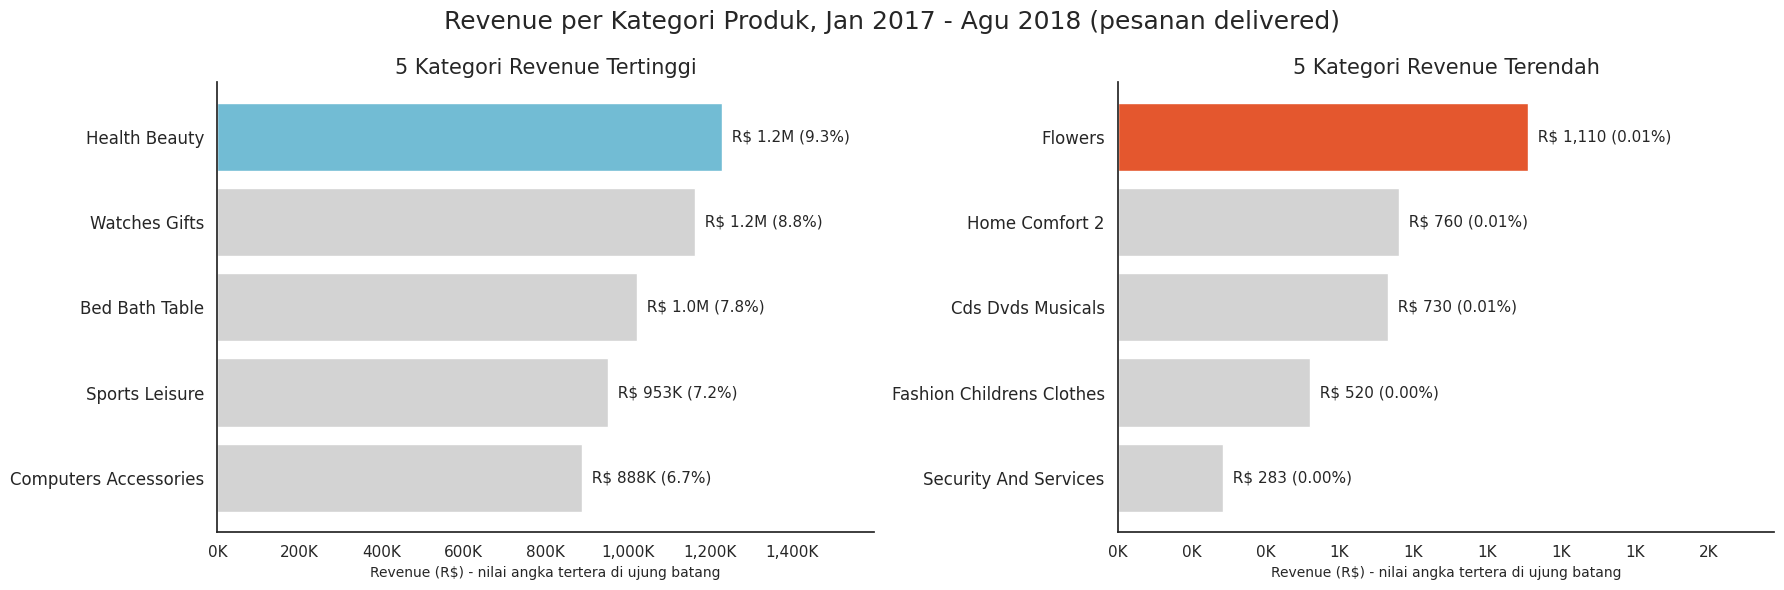

In [20]:
def money_fmt(x, pos=None):
    return f"R$ {x/1e3:,.0f}K" if x < 1e6 else f"R$ {x/1e6:,.1f}M"

top5 = category_df.head(5).iloc[::-1]
bottom5 = category_df.tail(5).iloc[::-1]

fig, ax = plt.subplots(1, 2, figsize=(18, 6))
bars = ax[0].barh(top5["category"], top5["revenue"], color=[MUTED] * 4 + [HIGHLIGHT])
for b, s in zip(bars, top5["share_pct"]):
    ax[0].text(b.get_width(), b.get_y() + b.get_height() / 2, f"  {money_fmt(b.get_width())} ({s:.1f}%)", va="center", fontsize=11)
ax[0].set_title("5 Kategori Revenue Tertinggi", fontsize=15)
ax[0].set_xlim(0, top5["revenue"].max() * 1.3)

bars = ax[1].barh(bottom5["category"], bottom5["revenue"], color=[MUTED] * 4 + [ALERT])
for b, s in zip(bars, bottom5["share_pct"]):
    ax[1].text(b.get_width(), b.get_y() + b.get_height() / 2, f"  R$ {b.get_width():,.0f} ({s:.2f}%)", va="center", fontsize=11)
ax[1].set_title("5 Kategori Revenue Terendah", fontsize=15)
ax[1].set_xlim(0, bottom5["revenue"].max() * 1.6)

for a in ax:
    a.set_xlabel("Revenue (R$) - nilai angka tertera di ujung batang", fontsize=10)
    a.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, p: f"{x/1e3:,.0f}K"))
    a.tick_params(axis="y", labelsize=12)
plt.suptitle("Revenue per Kategori Produk, Jan 2017 - Agu 2018 (pesanan delivered)", fontsize=18)
plt.tight_layout()
plt.show()

**Insight (Pertanyaan 1):**
- *Health Beauty* menjadi kategori revenue terbesar (R$ 1,23 juta; 9,3%), disusul *Watches Gifts* (R$ 1,16 juta; 8,8%) dan *Bed Bath Table* (R$ 1,02 juta; 7,8%).
- Terdapat perbedaan peringkat: *Bed Bath Table* memiliki jumlah item terjual terbanyak (10.945) tetapi revenue di urutan ketiga, karena harga per itemnya lebih rendah dibanding *Watches Gifts* (5.853 item namun revenue lebih tinggi).
- Lima kategori terbawah hanya menghasilkan antara R$ 283 dan R$ 1.110 selama hampir dua tahun, jauh di bawah ongkos operasional untuk mengelolanya.

### Pertanyaan 2: Tren order dan revenue bulanan

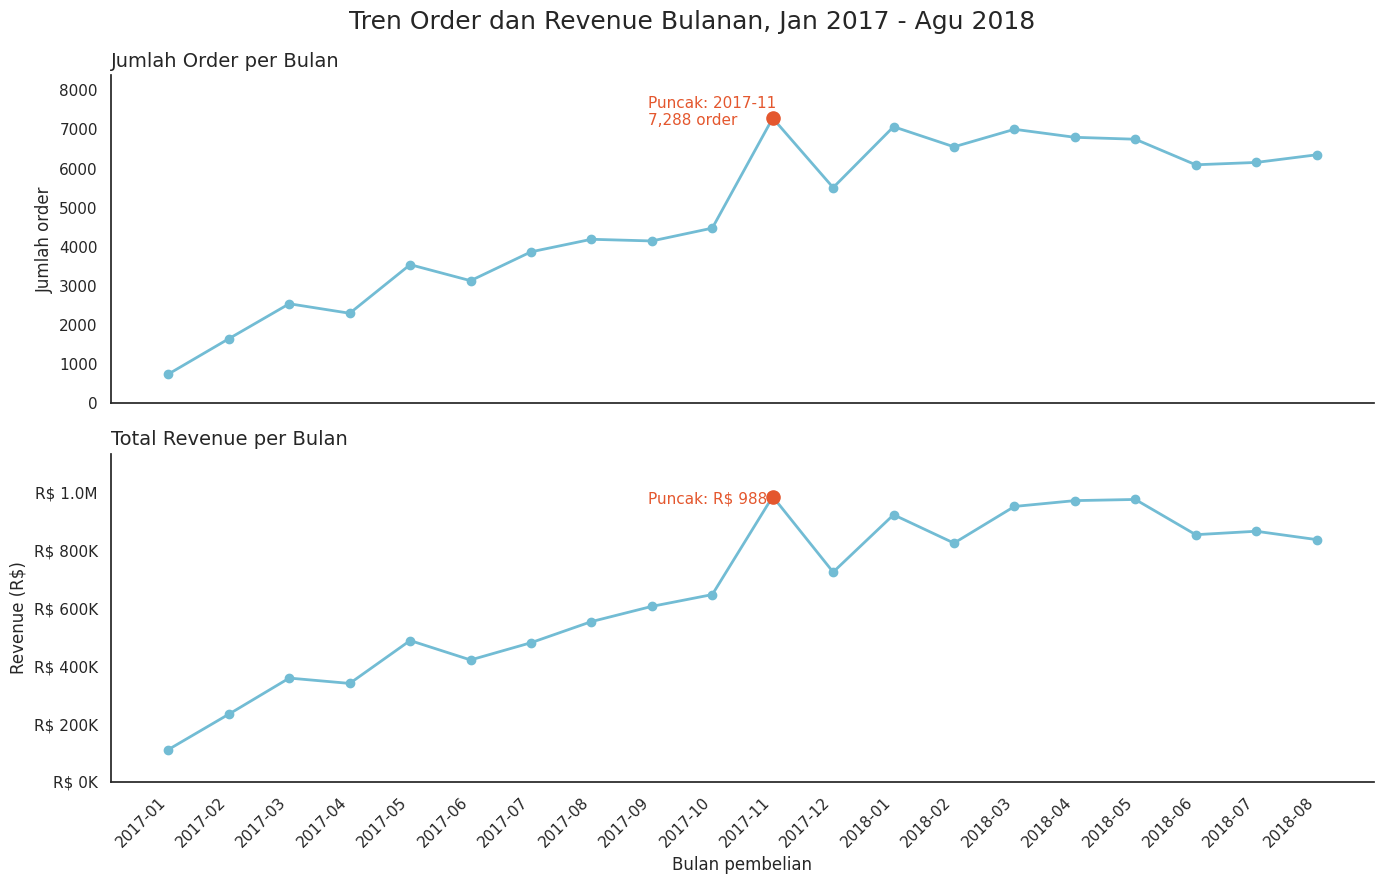

In [21]:
fig, ax = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
x = np.arange(len(monthly_df))
labels = monthly_df["order_month"]
pk = monthly_df["revenue"].idxmax()

ax[0].plot(x, monthly_df["order_count"], marker="o", linewidth=2, color=HIGHLIGHT)
ax[0].scatter(pk, monthly_df.loc[pk, "order_count"], color=ALERT, zorder=5, s=90)
ax[0].annotate(f"Puncak: {monthly_df.loc[pk, 'order_month']}\n{int(monthly_df.loc[pk, 'order_count']):,} order",
               (pk, monthly_df.loc[pk, "order_count"]), textcoords="offset points", xytext=(-90, -5), fontsize=11, color=ALERT)
ax[0].set_title("Jumlah Order per Bulan", fontsize=14, loc="left")
ax[0].set_ylabel("Jumlah order")
ax[0].set_ylim(0, monthly_df["order_count"].max() * 1.15)

ax[1].plot(x, monthly_df["revenue"], marker="o", linewidth=2, color=HIGHLIGHT)
ax[1].scatter(pk, monthly_df.loc[pk, "revenue"], color=ALERT, zorder=5, s=90)
ax[1].annotate(f"Puncak: {money_fmt(monthly_df.loc[pk, 'revenue'])}", (pk, monthly_df.loc[pk, "revenue"]),
               textcoords="offset points", xytext=(-90, -5), fontsize=11, color=ALERT)
ax[1].set_title("Total Revenue per Bulan", fontsize=14, loc="left")
ax[1].set_ylabel("Revenue (R$)")
ax[1].yaxis.set_major_formatter(mtick.FuncFormatter(money_fmt))
ax[1].set_ylim(0, monthly_df["revenue"].max() * 1.15)
ax[1].set_xticks(x)
ax[1].set_xticklabels(labels, rotation=45, ha="right")
ax[1].set_xlabel("Bulan pembelian")
plt.suptitle("Tren Order dan Revenue Bulanan, Jan 2017 - Agu 2018", fontsize=18)
plt.tight_layout()
plt.show()

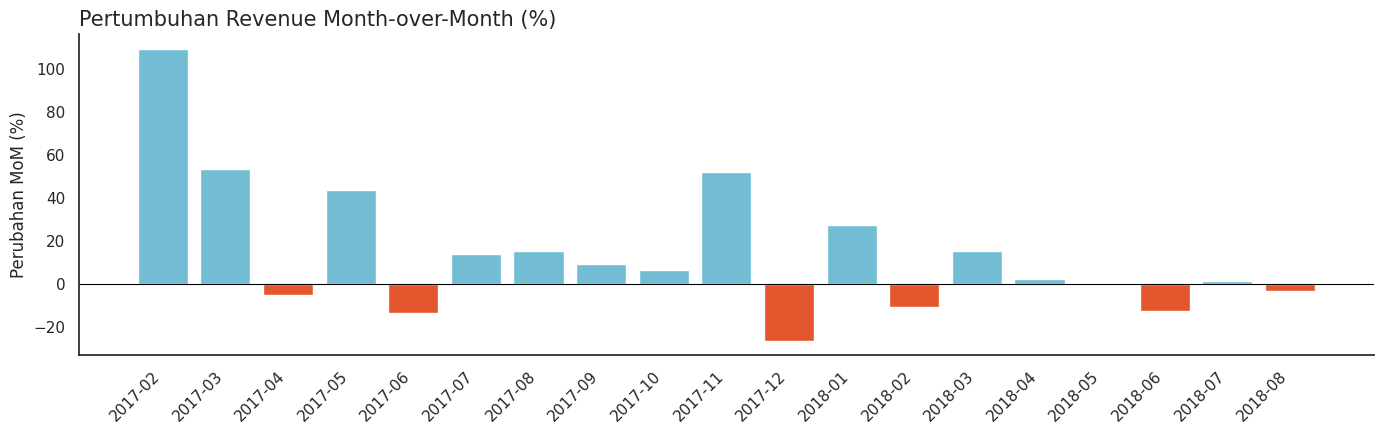

In [22]:
fig, ax = plt.subplots(figsize=(14, 4.5))
mom = monthly_df.dropna(subset=["revenue_mom_pct"])
ax.bar(mom["order_month"], mom["revenue_mom_pct"], color=[HIGHLIGHT if v >= 0 else ALERT for v in mom["revenue_mom_pct"]])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Pertumbuhan Revenue Month-over-Month (%)", fontsize=15, loc="left")
ax.set_ylabel("Perubahan MoM (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Insight (Pertanyaan 2):**
- Tren order dan revenue naik tajam sepanjang 2017 dan mencapai puncak pada **November 2017** (kemungkinan terkait momen belanja akhir tahun, mis. Black Friday; dataset tidak memuat data kampanye sehingga ini bersifat dugaan, bukan fakta).
- Desember 2017 turun 26,5% setelah lonjakan November, namun Januari 2018 kembali naik 27,4% sehingga November bukan sekadar anomali sesaat, melainkan puncak musiman.
- Sejak Januari 2018, pertumbuhan **mendatar**: order stagnan di 6.100-7.100 per bulan dan revenue Jun-Agu 2018 lebih rendah dari Apr-Mei 2018. Pertumbuhan eksplosif 2017 belum berlanjut di 2018.

### Pertanyaan 3: Skor review dan keterlambatan per state

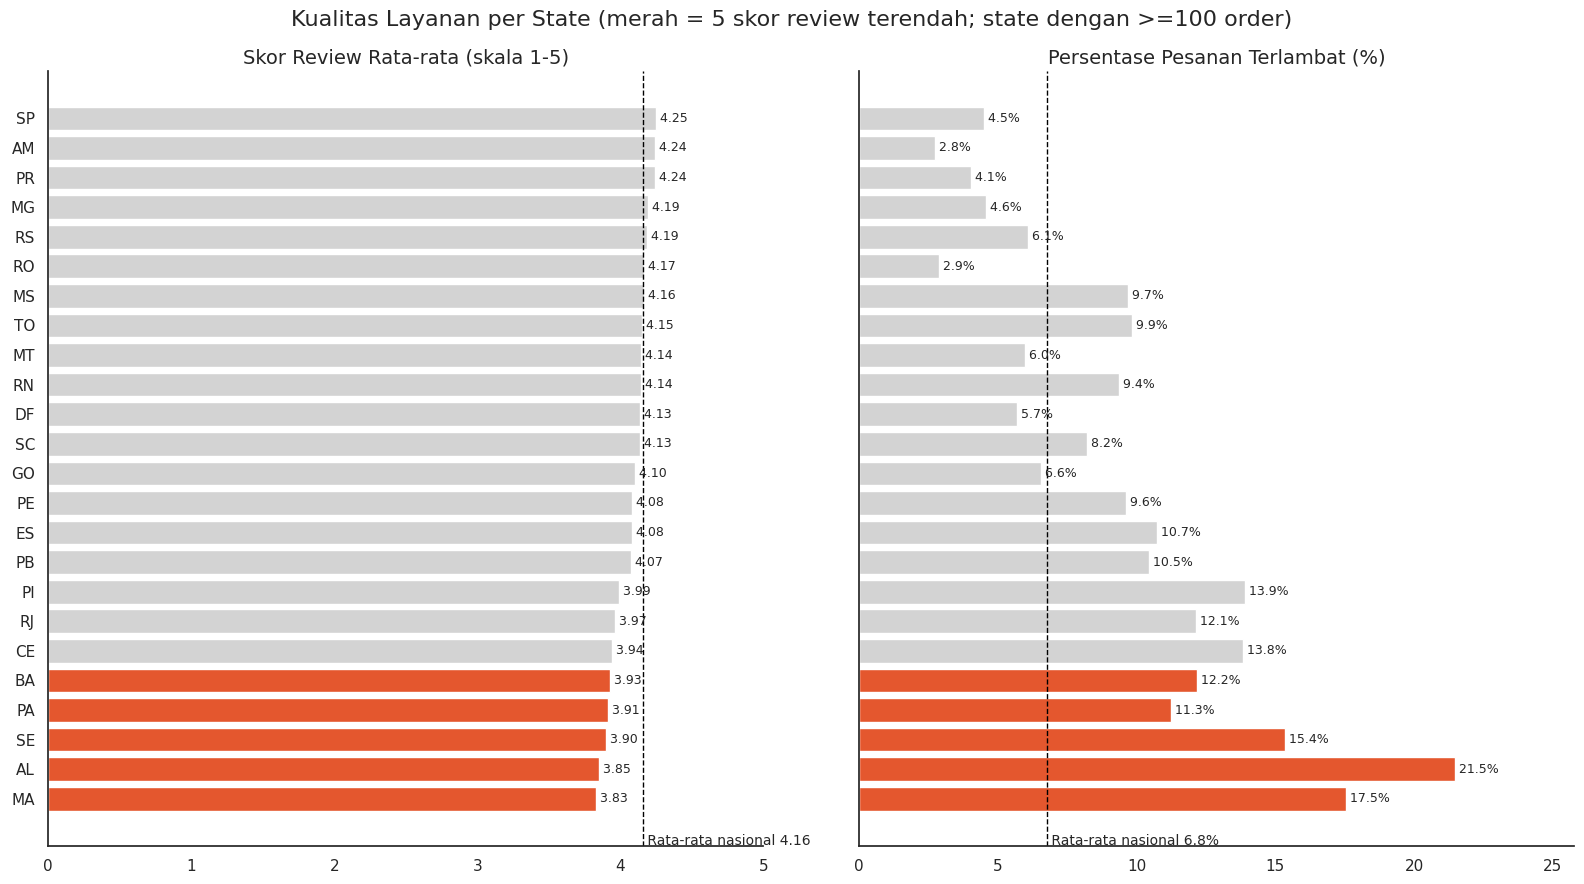

In [23]:
ordered = state_df.sort_values("avg_review", ascending=True).reset_index(drop=True)
lowest5 = set(ordered.head(5)["customer_state"])
colors_r = [ALERT if s in lowest5 else MUTED for s in ordered["customer_state"]]
nat_review = order_level["review_score"].mean()
nat_late = order_level["is_late"].mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(16, 9), sharey=True)
ax[0].barh(ordered["customer_state"], ordered["avg_review"], color=colors_r)
ax[0].axvline(nat_review, color="black", linestyle="--", linewidth=1)
ax[0].text(nat_review, -1.2, f" Rata-rata nasional {nat_review:.2f}", fontsize=10, va="top")
for i, v in enumerate(ordered["avg_review"]):
    ax[0].text(v, i, f" {v:.2f}", va="center", fontsize=9)
ax[0].set_xlim(0, 5)
ax[0].set_title("Skor Review Rata-rata (skala 1-5)", fontsize=14)

ax[1].barh(ordered["customer_state"], ordered["late_pct"], color=colors_r)
ax[1].axvline(nat_late, color="black", linestyle="--", linewidth=1)
ax[1].text(nat_late, -1.2, f" Rata-rata nasional {nat_late:.1f}%", fontsize=10, va="top")
for i, v in enumerate(ordered["late_pct"]):
    ax[1].text(v, i, f" {v:.1f}%", va="center", fontsize=9)
ax[1].set_xlim(0, ordered["late_pct"].max() * 1.2)
ax[1].set_title("Persentase Pesanan Terlambat (%)", fontsize=14)
plt.suptitle("Kualitas Layanan per State (merah = 5 skor review terendah; state dengan >=100 order)", fontsize=16)
plt.tight_layout()
plt.show()

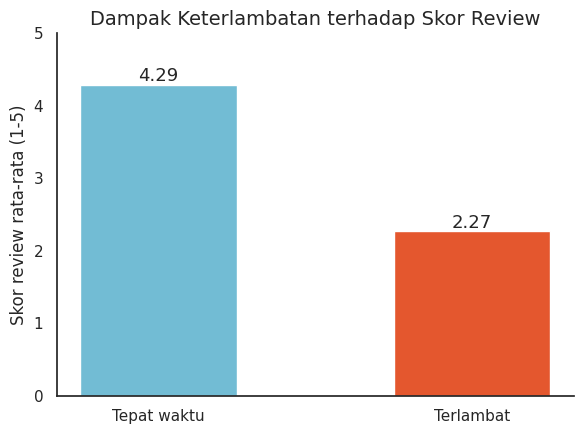

In [24]:
late_review = order_level.dropna(subset=["review_score"]).groupby("is_late")["review_score"].mean().rename(index={0: "Tepat waktu", 1: "Terlambat"})
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.bar(late_review.index, late_review.values, color=[HIGHLIGHT, ALERT], width=0.5)
for i, v in enumerate(late_review.values):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center", fontsize=13)
ax.set_ylim(0, 5)
ax.set_ylabel("Skor review rata-rata (1-5)")
ax.set_title("Dampak Keterlambatan terhadap Skor Review", fontsize=14)
plt.tight_layout()
plt.show()

**Insight (Pertanyaan 3):**
- Lima state dengan skor review terendah (MA, AL, SE, PA, BA) berada di wilayah **Utara dan Timur Laut** Brasil, secara geografis jauh dari konsentrasi pelanggan di Tenggara.
- **AL (21,5%)**, **MA (17,5%)**, dan **SE (15,4%)** memiliki persentase pesanan terlambat 2-3 kali lipat rata-rata nasional (6,8%).
- Pesanan terlambat menurunkan skor review rata-rata dari 4,29 menjadi 2,27 (selisih sekitar 2 poin), sehingga masalah utama kepuasan pelanggan adalah **keterlambatan, bukan kualitas produk**.

## Analisis Lanjutan

Tiga teknik analisis lanjutan (tanpa *machine learning*) diterapkan karena relevan dengan data transaksi marketplace:

1. **RFM Analysis** - tujuannya mengelompokkan pelanggan (`customer_unique_id`) menurut perilaku belanja: *Recency* (hari sejak pembelian terakhir), *Frequency* (jumlah order unik), dan *Monetary* (total belanja). Hasilnya dipakai untuk menentukan pelanggan mana yang layak dipertahankan atau diaktifkan kembali.
2. **Clustering manual (manual grouping & binning)** - segmen pelanggan dibuat dengan aturan bisnis dari skor RFM, dan lama pengiriman dikelompokkan ke dalam *bin* (`pd.cut`) untuk melihat batas waktu pengiriman yang mulai menurunkan kepuasan.
3. **Geospatial Analysis** - memetakan jumlah pelanggan dan skor review per state menggunakan koordinat (lintang/bujur) untuk melihat pola sebaran geografis.

### RFM Analysis dan segmentasi manual

In [25]:
ref_date = all_df["order_purchase_timestamp"].max().normalize() + pd.Timedelta(days=1)
rfm_df = (all_df.groupby("customer_unique_id")
          .agg(last_order=("order_purchase_timestamp", "max"), frequency=("order_id", "nunique"), monetary=("price", "sum"))
          .reset_index())
rfm_df["recency"] = (ref_date - rfm_df["last_order"].dt.normalize()).dt.days
rfm_df = rfm_df.drop(columns="last_order")

# Manual grouping berdasarkan aturan bisnis
rfm_df["monetary_pct"] = rfm_df["monetary"].rank(pct=True, method="first")
rfm_df["monetary_group"] = pd.cut(rfm_df["monetary_pct"], [0, 1/3, 2/3, 1], labels=["Low", "Mid", "High"], include_lowest=True)
rfm_df["segment"] = np.select(
    [rfm_df["frequency"] >= 2,
     (rfm_df["recency"] <= 180) & (rfm_df["monetary_group"] == "High"),
     (rfm_df["recency"] <= 180),
     (rfm_df["monetary_group"] == "High")],
    ["Loyal (repeat buyer)", "Active High Value", "Active Regular", "At-Risk High Value"],
    default="Lost / Dormant")

display(rfm_df[["recency", "frequency", "monetary"]].describe().round(2))
seg_df = (rfm_df.groupby("segment").agg(customers=("customer_unique_id", "count"), revenue=("monetary", "sum"),
                                         avg_recency=("recency", "mean"), avg_monetary=("monetary", "mean")).reset_index())
seg_df["customer_pct"] = seg_df["customers"] / seg_df["customers"].sum() * 100
seg_df["revenue_pct"] = seg_df["revenue"] / seg_df["revenue"].sum() * 100
seg_df = seg_df.sort_values("revenue", ascending=False)
display(rnd(seg_df, 1))
print(f"Pelanggan yang membeli lebih dari 1 kali: {(rfm_df['frequency'] >= 2).mean():.1%}")

,recency,frequency,monetary
count,93096.00,93096.00,93096.00
mean,237.25,1.03,141.57
std,150.94,0.21,215.77
min,1.00,1.00,0.85
25%,115.00,1.00,47.65
50%,219.00,1.00,89.70
75%,346.00,1.00,154.16
max,602.00,15.00,13440.00


,segment,customers,revenue,avg_recency,avg_monetary,customer_pct,revenue_pct
2,At-Risk High Value,17121,5068785.6,336.9,296.1,18.4,38.5
0,Active High Value,11996,3610081.1,93.8,300.9,12.9,27.4
3,Lost / Dormant,36441,2230755.0,337.8,61.2,39.1,16.9
1,Active Regular,24749,1544801.2,91.7,62.4,26.6,11.7
4,Loyal (repeat buyer),2789,725355.0,220.1,260.1,3.0,5.5


Pelanggan yang membeli lebih dari 1 kali: 3.0%


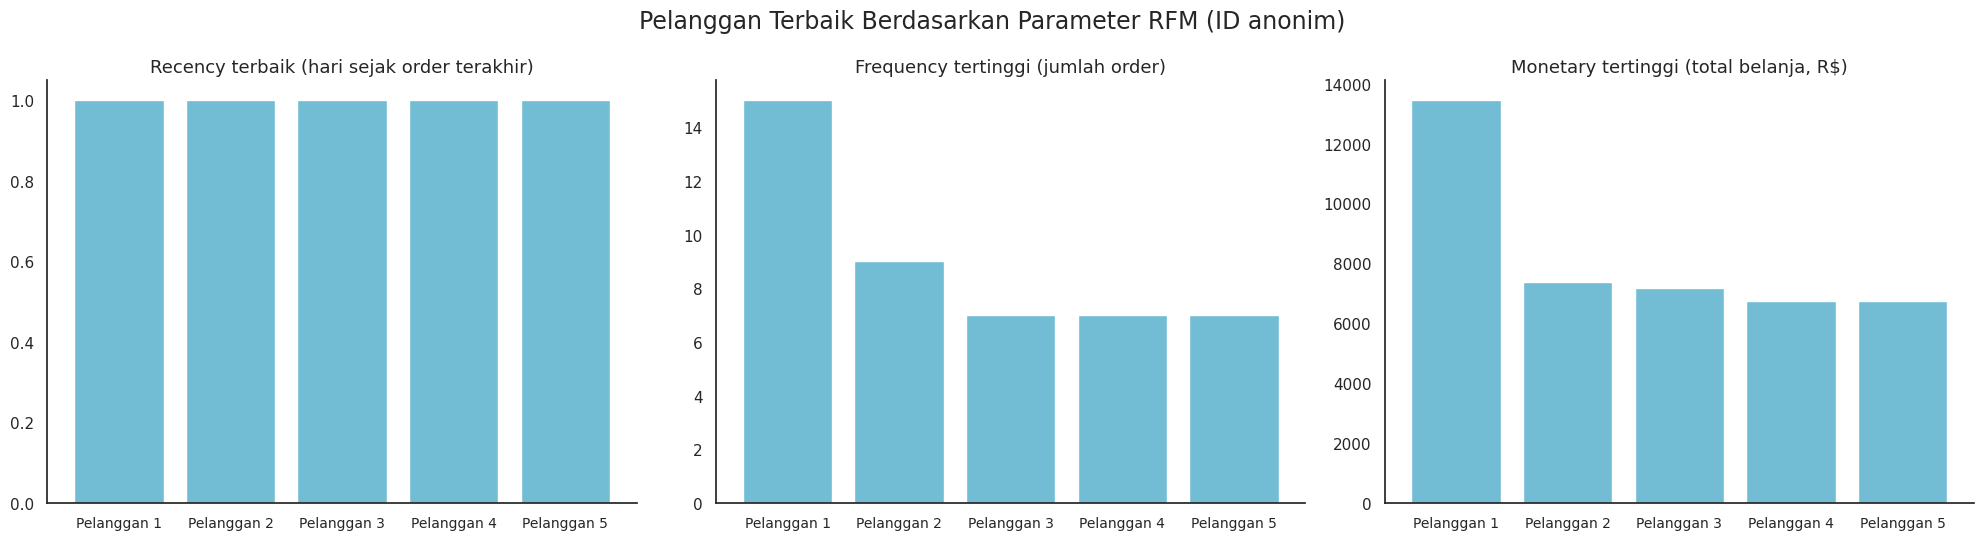

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
best = rfm_df.sort_values("recency").head(5)
ax[0].bar(range(5), best["recency"], color=HIGHLIGHT)
ax[0].set_title("Recency terbaik (hari sejak order terakhir)", fontsize=13)
best = rfm_df.sort_values("frequency", ascending=False).head(5)
ax[1].bar(range(5), best["frequency"], color=HIGHLIGHT)
ax[1].set_title("Frequency tertinggi (jumlah order)", fontsize=13)
best = rfm_df.sort_values("monetary", ascending=False).head(5)
ax[2].bar(range(5), best["monetary"], color=HIGHLIGHT)
ax[2].set_title("Monetary tertinggi (total belanja, R$)", fontsize=13)
for a in ax:
    a.set_xticks(range(5)); a.set_xticklabels([f"Pelanggan {i+1}" for i in range(5)], fontsize=10)
    a.set_ylim(bottom=0)
plt.suptitle("Pelanggan Terbaik Berdasarkan Parameter RFM (ID anonim)", fontsize=17)
plt.tight_layout()
plt.show()

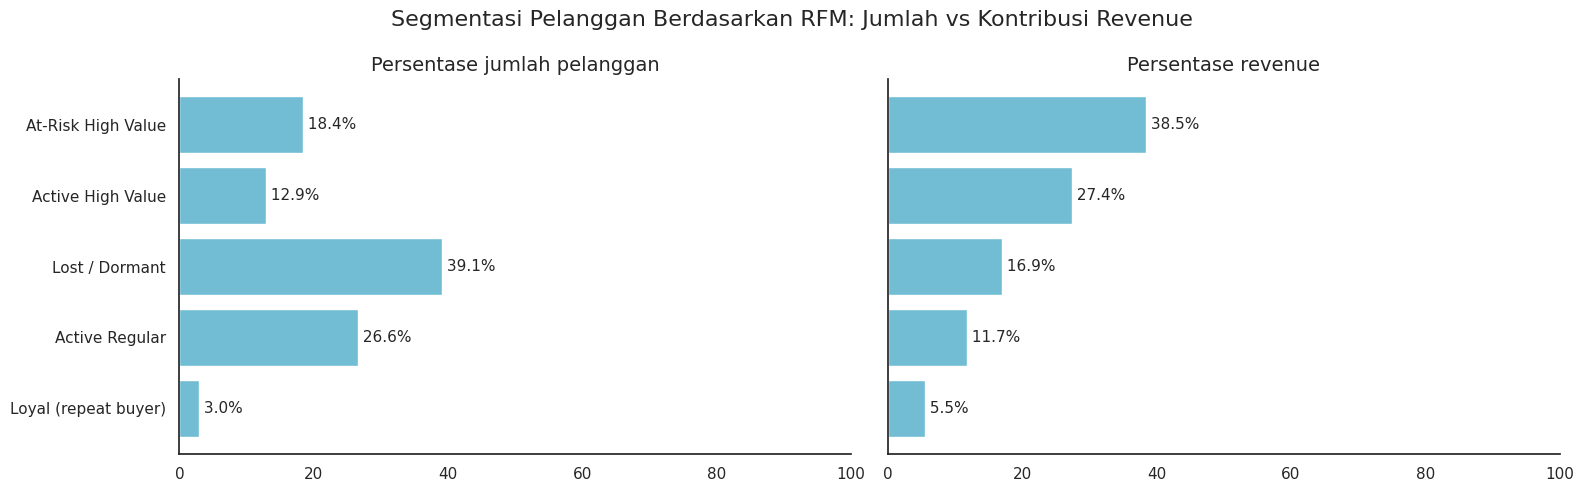

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
order_seg = seg_df.sort_values("revenue_pct")["segment"].tolist()
d = seg_df.set_index("segment").loc[order_seg]
ax[0].barh(order_seg, d["customer_pct"], color=HIGHLIGHT)
ax[1].barh(order_seg, d["revenue_pct"], color=HIGHLIGHT)
for a, col in zip(ax, ["customer_pct", "revenue_pct"]):
    for i, v in enumerate(d[col]):
        a.text(v, i, f" {v:.1f}%", va="center", fontsize=11)
    a.set_xlim(0, 100)
ax[0].set_title("Persentase jumlah pelanggan", fontsize=14)
ax[1].set_title("Persentase revenue", fontsize=14)
plt.suptitle("Segmentasi Pelanggan Berdasarkan RFM: Jumlah vs Kontribusi Revenue", fontsize=16)
plt.tight_layout()
plt.show()

**Insight:**
- Hanya **3,0%** pelanggan yang pernah membeli lebih dari satu kali, dan median *recency* adalah 219 hari. Pelanggan Olist cenderung membeli sekali lalu tidak kembali.
- Segmen **At-Risk High Value** (belanja besar, tidak aktif > 180 hari) adalah **18,4% pelanggan namun 38,5% revenue**, kontribusi revenue terbesar.
- **Active High Value** (12,9% pelanggan) menyumbang 27,4% revenue. Dua segmen *high value* ini bersama-sama menghasilkan sekitar dua pertiga revenue dari 31% pelanggan.
- Segmen **Lost / Dormant** adalah yang terbesar (39,1% pelanggan) tetapi hanya 16,9% revenue, sehingga prioritas pemasaran ulang sebaiknya tidak pada segmen ini.

### Binning: lama pengiriman vs skor review

,delivery_bin,orders,avg_review
0,0-7 hari,33488,4.41
1,8-14 hari,36126,4.29
2,15-21 hari,15201,4.10
3,22-30 hari,6777,3.49
4,>30 hari,3968,2.16


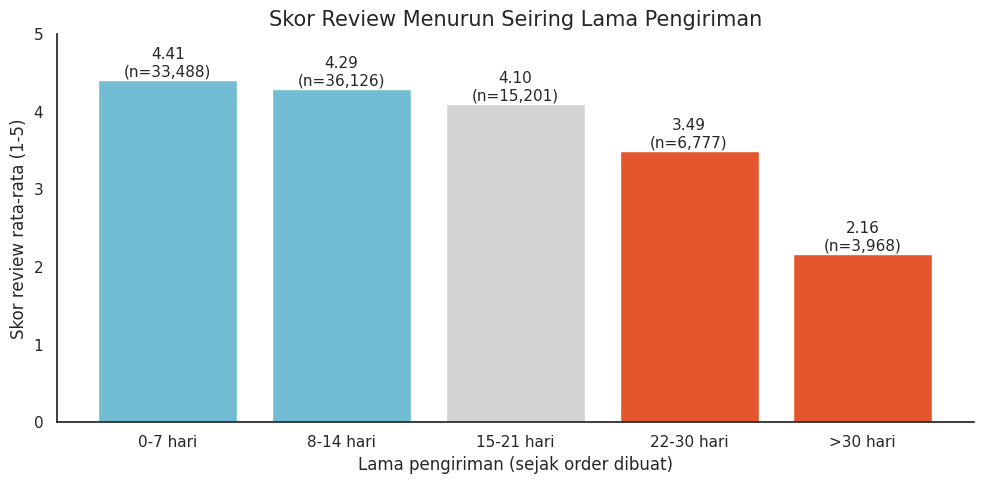

In [28]:
order_level = all_df.drop_duplicates("order_id").dropna(subset=["review_score"]).copy()
bins = [-1, 7, 14, 21, 30, np.inf]
names = ["0-7 hari", "8-14 hari", "15-21 hari", "22-30 hari", ">30 hari"]
order_level["delivery_bin"] = pd.cut(order_level["delivery_days"], bins=bins, labels=names)
bin_df = order_level.groupby("delivery_bin").agg(orders=("order_id", "count"), avg_review=("review_score", "mean")).reset_index()
display(rnd(bin_df))

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(bin_df["delivery_bin"].astype(str), bin_df["avg_review"], color=[HIGHLIGHT, HIGHLIGHT, MUTED, ALERT, ALERT])
for i, (v, n) in enumerate(zip(bin_df["avg_review"], bin_df["orders"])):
    ax.text(i, v + 0.05, f"{v:.2f}\n(n={n:,})", ha="center", fontsize=11)
ax.set_ylim(0, 5)
ax.set_ylabel("Skor review rata-rata (1-5)")
ax.set_xlabel("Lama pengiriman (sejak order dibuat)")
ax.set_title("Skor Review Menurun Seiring Lama Pengiriman", fontsize=15)
plt.tight_layout()
plt.show()

**Insight:**
- Skor review turun bertahap seiring lama pengiriman: 4,41 (0-7 hari), 4,29 (8-14 hari), 4,10 (15-21 hari), lalu anjlok ke **3,49 (22-30 hari)** dan **2,16 (> 30 hari)**.
- Titik kritis berada di sekitar **21 hari**. Sebanyak 10.745 order ber-review (sekitar 11%) berada di atas batas tersebut.

### Geospatial Analysis: sebaran pelanggan dan skor review per state

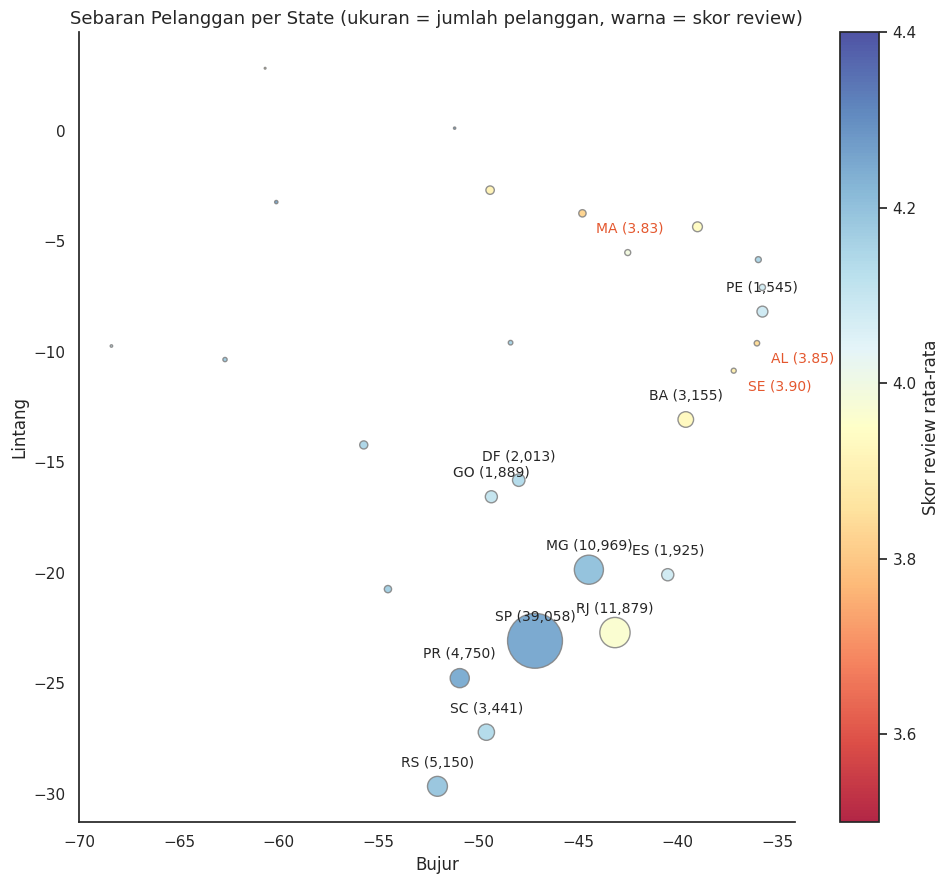

In [29]:
geo_state = (all_df.drop_duplicates("order_id").groupby("customer_state")
             .agg(customers=("customer_unique_id", "nunique"), avg_review=("review_score", "mean"), orders=("order_id", "nunique"))
             .reset_index().merge(state_geo, left_on="customer_state", right_on="state"))

fig, ax = plt.subplots(figsize=(10, 9))
sc = ax.scatter(geo_state["lng"], geo_state["lat"], s=geo_state["customers"] / 25, c=geo_state["avg_review"],
                cmap="RdYlBu", vmin=3.5, vmax=4.4, alpha=0.85, edgecolor="grey")
for _, r in geo_state[geo_state["customers"] > 1500].iterrows():
    ax.annotate(f"{r['customer_state']} ({r['customers']:,})", (r["lng"], r["lat"]), fontsize=10, ha="center", va="bottom", xytext=(0, 12), textcoords="offset points")
for _, r in geo_state[geo_state["orders"] >= 100].sort_values("avg_review").head(3).iterrows():
    ax.annotate(f"{r['customer_state']} ({r['avg_review']:.2f})", (r["lng"], r["lat"]), fontsize=10, color=ALERT, xytext=(10, -14), textcoords="offset points")
plt.colorbar(sc, label="Skor review rata-rata")
ax.set_xlabel("Bujur"); ax.set_ylabel("Lintang")
ax.set_title("Sebaran Pelanggan per State (ukuran = jumlah pelanggan, warna = skor review)", fontsize=13)
plt.tight_layout()
plt.show()

**Insight:**
- Pelanggan sangat terkonsentrasi di Tenggara: **SP (39.058 pelanggan, sekitar 42%)**, RJ (11.879), dan MG (10.969), bersama-sama sekitar dua pertiga seluruh pelanggan.
- Pada peta, state di Utara dan Timur Laut (MA, AL, SE, BA, PA) tampak berwarna kuning-oranye (skor lebih rendah) dengan jumlah pelanggan relatif kecil, sedangkan SP, PR, dan MG berwarna biru (skor lebih tinggi). Skor review cenderung lebih baik di wilayah Tenggara dan Selatan.
- RJ memiliki volume besar tetapi skor review hanya 3,97, sehingga RJ layak menjadi prioritas perbaikan tersendiri karena dampaknya pada jumlah pelanggan yang banyak.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Revenue sangat terkonsentrasi. Lima kategori teratas (*Health Beauty*, *Watches Gifts*, *Bed Bath Table*, *Sports Leisure*, *Computers Accessories*) menyumbang ~39,9% dari R$ 13,18 juta, dan hanya 18 dari 74 kategori menghasilkan 80% revenue. Lima kategori terbawah (mis. *Security And Services*, R$ 283) hampir tidak berkontribusi (< 0,01%).
- **Conclusion pertanyaan 2:** Order dan revenue tumbuh pesat sepanjang 2017 hingga puncak **November 2017 (7.288 order; R$ 987,6 ribu)**, lalu turun 26,5% di Desember. Sepanjang Jan-Agu 2018 revenue naik 141% dibanding periode yang sama 2017, tetapi pertumbuhan bulanan mendatar dan melemah pada Jun-Agu 2018.
- **Conclusion pertanyaan 3:** Skor review terendah ada di **MA (3,83), AL (3,85), SE (3,90), PA (3,91), BA (3,93)**. AL, MA, dan SE memiliki % keterlambatan 15-21% (rata-rata nasional 6,8%). Pesanan terlambat mendapat skor 2,27 vs 4,29 untuk yang tepat waktu, dan skor anjlok saat pengiriman melewati 21 hari. Keterlambatan adalah penyebab utama kepuasan rendah (korelasi antar state -0,91, bersifat asosiasi dan bukan bukti sebab-akibat).
- **Insight analisis lanjutan:** hanya 3,0% pelanggan membeli ulang; segmen *At-Risk High Value* (18,4% pelanggan) menyimpan 38,5% revenue.

**Rekomendasi Action Item:**
1. **Prioritaskan stok dan promosi pada kategori inti.** Pastikan ketersediaan stok dan alokasi iklan pada 5 kategori teratas serta 18 kategori yang menghasilkan 80% revenue. Tinjau ulang (rasionalisasi atau gabungkan) kategori dengan revenue di bawah R$ 1.500 yang hampir tidak berkontribusi.
2. **Siapkan kapasitas dan kampanye musiman sebelum November.** Tambah kapasitas gudang, kurir, dan layanan pelanggan mulai Oktober, dan rencanakan kampanye khusus untuk menahan penurunan pasca puncak (Desember) serta menghidupkan kembali pertumbuhan yang mendatar sejak 2018.
3. **Tekan keterlambatan pengiriman di MA, AL, SE, PA, BA, dan RJ.** Tinjau kurir/rute di wilayah tersebut atau tambah titik penyimpanan yang lebih dekat. Sementara itu, perbarui estimasi pengiriman agar lebih realistis di wilayah tersebut, dan jadikan **21 hari** sebagai batas SLA internal karena skor review anjlok di atas batas ini. Targetkan penurunan % terlambat di AL/MA dari 17-21% mendekati rata-rata nasional (~7%).
4. **Aktifkan kembali pelanggan *At-Risk High Value*.** Kirim voucher/email *win-back* kepada ±17 ribu pelanggan ini (kontribusi revenue 38,5%), dan buat program loyalitas untuk mengubah pembeli sekali menjadi pembeli ulang (saat ini hanya 3,0%). Hindari anggaran besar pada segmen *Lost / Dormant* yang bernilai rendah.